# Artefact-corrected BVOC split (design B)

Closed split of the land-cover response into a **BVOC** and a **non-BVOC** part, with the fBVOC prescription artefact removed by the matched baseline (design B, user decision 2026-10-30; `analysis/FBVOC_ARTEFACT.md` §4–5).

For each period P (PD, FUT), reference emissions E = ctrlP (the run's own CTRL climatology):

| Term | Formula | Runs |
|---|---|---|
| **Total** | LCC_P − CTRL_P | interactive |
| **art_CTRL,P** | CTRL_P^ctrlP − CTRL_P | artefact on CTRL land |
| **BVOC (corrected)** | (LCC_P − LCC_P^ctrlP) + art_CTRL,P | 4 runs |
| **non-BVOC** | LCC_P^ctrlP − CTRL_P^ctrlP | both prescribed, same emissions |
| BVOC (uncorrected, for comparison) | LCC_P − LCC_P^ctrlP | old `BVOC_PAIRS` contrast |

Total = non-BVOC + BVOC (corrected) holds exactly for every linear field. The corrected BVOC term is computed as LCC_P − V with the virtual run V = LCC_P^ctrlP − CTRL_P^ctrlP + CTRL_P (`forcing_maps.VirtualRun`, `corrected_fbvoc`, `CORRECTED_PAIRS`), so every existing map function works unchanged.

**What the terms contain (FBVOC_ARTEFACT.md §7).** BVOC = the change in emissions between LCC and CTRL with interactive MEGAN (new vegetation **and** MEGAN's response to the changed climate over the new forest). non-BVOC = every land effect not going through BVOC emissions (albedo, ET, dry deposition, …).

**Assumptions.** (i) The artefact does not depend on which emissions are prescribed; (ii) δ ≈ 0: the artefact on LCC land ≈ that on CTRL land. (ii) is **not settled**: the PD test (`how_big_artefact_is_PD.ipynb`, 2001–02 only) gives R = 0.81 globally; its robustness is checked in `artefact-robustness.ipynb`.

**Caveats.** New chain (CO₂-fix spin-ups), 2001–2014, first 12 months dropped; mean ± 95 % t-interval over 14 paired years (4 runs per corrected contrast → ≈ √2 more noise than a 2-run contrast; the interval over the yearly combined series includes it). The clear-sky **surface albedo proxy** is not additive across pairs (each pair is weighted by its own insolation): it is shown for the Total only, as before.

Outputs: `results/figures/artefact-corrected-split/`, `results/tables/artefact-corrected-split/`.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from boreal_forest_expansion.plotting.style import set_default_style
from boreal_forest_expansion.plotting import forcing_maps as fm
from boreal_forest_expansion.plotting import palette as pal

set_default_style()
pd.set_option("display.width", 220, "display.max_rows", 300, "display.max_columns", 30)
START_YEAR, END_YEAR = 2001, 2014
STEM = "artefact-corrected-split"
FIG = fm.REPO_DIR / "results" / "figures" / STEM
TAB = fm.REPO_DIR / "results" / "tables" / STEM
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
common = dict(start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=True, figdir=FIG)

def contrasts(P):
    # label -> (case1, case2); case2 of "BVOC corrected" is the VirtualRun
    cp = fm.CORRECTED_PAIRS[P]
    lcc, ctrl, lcc_e, ctrl_e = f"LCC_{P}", f"CTRL_{P}", f"LCC_{P}_fBVOCctrl{P}", f"CTRL_{P}_fBVOCctrl{P}"
    return {"Total": (lcc, ctrl), "non-BVOC": (lcc_e, ctrl_e), "BVOC corrected": (lcc, cp["fbvoc"]),
            "BVOC uncorrected": (lcc, lcc_e), "artefact art_CTRL": (ctrl_e, ctrl)}

for P in ("PD", "FUT"):
    print(P, {k: f"{a} − {b}" for k, (a, b) in contrasts(P).items()})
    print("   V weights:", fm.CORRECTED_PAIRS[P]["fbvoc"].weights)
    for alias in fm.CORRECTED_PAIRS[P]["fbvoc"].weights | {f"LCC_{P}": 1}:
        for comp, cls in (("atm", "RADIATIVE"), ("atm", "SOA"), ("atm", "CLOUDPROP"), ("atm", "BVOC"), ("lnd", "ET")):
            p = fm.filename(alias, cls, START_YEAR, END_YEAR, comp)
            assert p.exists(), f"MISSING {p}"
print("all input files present ✓")

PD {'Total': 'LCC_PD − CTRL_PD', 'non-BVOC': 'LCC_PD_fBVOCctrlPD − CTRL_PD_fBVOCctrlPD', 'BVOC corrected': 'LCC_PD − LCC_PD_fBVOCctrlPD_corr', 'BVOC uncorrected': 'LCC_PD − LCC_PD_fBVOCctrlPD', 'artefact art_CTRL': 'CTRL_PD_fBVOCctrlPD − CTRL_PD'}
   V weights: {'LCC_PD_fBVOCctrlPD': 1.0, 'CTRL_PD_fBVOCctrlPD': -1.0, 'CTRL_PD': 1.0}
FUT {'Total': 'LCC_FUT − CTRL_FUT', 'non-BVOC': 'LCC_FUT_fBVOCctrlFUT − CTRL_FUT_fBVOCctrlFUT', 'BVOC corrected': 'LCC_FUT − LCC_FUT_fBVOCctrlFUT_corr', 'BVOC uncorrected': 'LCC_FUT − LCC_FUT_fBVOCctrlFUT', 'artefact art_CTRL': 'CTRL_FUT_fBVOCctrlFUT − CTRL_FUT'}
   V weights: {'LCC_FUT_fBVOCctrlFUT': 1.0, 'CTRL_FUT_fBVOCctrlFUT': -1.0, 'CTRL_FUT': 1.0}
all input files present ✓


## 1. Radiative budget per term and closure check
Yearly regional means (area-weighted, same masks for every contrast): global, ≥45°N, modified cells. Ghan terms: total (toa), ARI (dir), cloud, clear-clean (rest); NET, SW, LW. The closure Total − (non-BVOC + BVOC corrected) is checked year by year **before** any averaging.

In [2]:
REGIONS = ("global", "≥45°N", "modified cells")

def masks_for(ds):
    m = fm.region_masks(ds)
    m["global"] = xr.ones_like(m["≥45°N"], dtype=bool)
    return m

rows = []
for P in ("PD", "FUT"):
    ref = fm.open_class(f"CTRL_{P}", "RADIATIVE", START_YEAR, END_YEAR)
    masks = masks_for(ref)
    for label, (c1, c2) in contrasts(P).items():
        for band in ("NET", "SW", "LW"):
            for term in fm.GHAN_TERMS:
                d = fm.yearly_difference(c1, c2, "RADIATIVE", f"{band}_{term}", START_YEAR, END_YEAR).load()
                for region in REGIONS:
                    r = fm.regional(d, ref, masks[region])
                    rows += [dict(period=P, region=region, contrast=label, band=band, term=term, year=int(y), value=float(v))
                             for y, v in zip(r["year"].values, r.values)]
rad = pd.DataFrame(rows)

# closure: Total = non-BVOC + BVOC corrected (yearly, before averaging); Ghan: dir + cloud + rest = toa
w = rad.pivot_table(index=["period", "region", "band", "term", "year"], columns="contrast", values="value")
err_split = (w["Total"] - w["non-BVOC"] - w["BVOC corrected"]).abs().max()
err_corr = (w["BVOC corrected"] - w["BVOC uncorrected"] - w["artefact art_CTRL"]).abs().max()
g = rad.pivot_table(index=["period", "region", "band", "year", "contrast"], columns="term", values="value")
err_ghan = (g["dir"] + g["cloud"] + g["rest"] - g["toa"]).abs().max()
print(f"closure Total − (non-BVOC + BVOC corr): {err_split:.1e} W m-2")
print(f"BVOC corr − (uncorr + art):              {err_corr:.1e} W m-2")
print(f"Ghan dir + cloud + rest − toa:           {err_ghan:.1e} W m-2")
assert max(err_split, err_corr) < 1e-6 and err_ghan < 1e-3

rad.to_csv(TAB / f"radiative_budget_split_yearly_{START_YEAR}_{END_YEAR}.csv", index=False)
rad_s = fm.summarize_years(rad, ["period", "region", "contrast", "band", "term"])
rad_s.to_csv(TAB / f"radiative_budget_split_{START_YEAR}_{END_YEAR}.csv", index=False)
ORDER = list(contrasts("PD"))
tab = rad_s[rad_s.band == "NET"].assign(v=lambda t: t["mean"].map("{:+.3f}".format) + " ± " + t["ci95"].map("{:.3f}".format))
tab.pivot_table(index=["region", "period", "contrast"], columns="term", values="v", aggfunc="first") \
   .reindex(columns=list(fm.GHAN_TERMS)).reindex(ORDER, level=2)

closure Total − (non-BVOC + BVOC corr): 2.7e-15 W m-2
BVOC corr − (uncorr + art):              1.5e-15 W m-2
Ghan dir + cloud + rest − toa:           1.4e-07 W m-2


term                                                toa             dir           cloud            rest
region         period contrast                                                                         
global         FUT    Total              +0.014 ± 0.018  -0.011 ± 0.012  -0.006 ± 0.015  +0.031 ± 0.010
                      non-BVOC           +0.036 ± 0.032  -0.004 ± 0.017  -0.001 ± 0.017  +0.041 ± 0.011
                      BVOC corrected     -0.022 ± 0.042  -0.006 ± 0.016  -0.005 ± 0.025  -0.010 ± 0.018
                      BVOC uncorrected   +0.017 ± 0.033  -0.001 ± 0.015  +0.025 ± 0.027  -0.007 ± 0.014
                      artefact art_CTRL  -0.039 ± 0.028  -0.006 ± 0.010  -0.030 ± 0.023  -0.003 ± 0.015
               PD     Total              +0.031 ± 0.024  -0.001 ± 0.006  -0.007 ± 0.021  +0.039 ± 0.007
                      non-BVOC           +0.034 ± 0.032  +0.001 ± 0.009  -0.009 ± 0.023  +0.042 ± 0.010
                      BVOC corrected     -0.003 ± 0.036  -0.002 ± 0.007  +0.002 ± 0.031  -0.003 ± 0.013
                      BVOC uncorrected   +0.046 ± 0.020  +0.005 ± 0.007  +0.036 ± 0.019  +0.006 ± 0.010
                      artefact art_CTRL  -0.049 ± 0.023  -0.007 ± 0.006  -0.034 ± 0.017  -0.009 ± 0.009
modified cells FUT    Total              +0.500 ± 0.051  -0.027 ± 0.008  -0.076 ± 0.041  +0.603 ± 0.023
                      non-BVOC           +0.566 ± 0.051  -0.026 ± 0.011  -0.029 ± 0.040  +0.620 ± 0.026
                      BVOC corrected     -0.065 ± 0.059  -0.001 ± 0.014  -0.047 ± 0.046  -0.017 ± 0.012
                      BVOC uncorrected   +0.034 ± 0.057  -0.002 ± 0.012  +0.057 ± 0.059  -0.021 ± 0.013
                      artefact art_CTRL  -0.100 ± 0.057  +0.001 ± 0.006  -0.104 ± 0.047  +0.003 ± 0.013
               PD     Total              +0.541 ± 0.040  -0.032 ± 0.007  -0.205 ± 0.039  +0.777 ± 0.035
                      non-BVOC           +0.587 ± 0.040  -0.033 ± 0.006  -0.177 ± 0.043  +0.797 ± 0.047
                      BVOC corrected     -0.046 ± 0.062  +0.002 ± 0.004  -0.029 ± 0.064  -0.019 ± 0.028
                      BVOC uncorrected   +0.037 ± 0.049  +0.004 ± 0.005  +0.046 ± 0.043  -0.012 ± 0.020
                      artefact art_CTRL  -0.084 ± 0.032  -0.002 ± 0.005  -0.074 ± 0.036  -0.007 ± 0.018
≥45°N          FUT    Total              +0.200 ± 0.029  -0.012 ± 0.009  -0.023 ± 0.018  +0.235 ± 0.011
                      non-BVOC           +0.257 ± 0.039  -0.009 ± 0.013  +0.016 ± 0.029  +0.250 ± 0.016
                      BVOC corrected     -0.056 ± 0.045  -0.003 ± 0.016  -0.039 ± 0.032  -0.015 ± 0.012
                      BVOC uncorrected   +0.031 ± 0.040  -0.002 ± 0.014  +0.045 ± 0.044  -0.012 ± 0.013
                      artefact art_CTRL  -0.087 ± 0.046  -0.000 ± 0.006  -0.084 ± 0.042  -0.003 ± 0.013
               PD     Total              +0.240 ± 0.031  -0.012 ± 0.008  -0.060 ± 0.027  +0.312 ± 0.017
                      non-BVOC           +0.268 ± 0.029  -0.014 ± 0.006  -0.041 ± 0.023  +0.322 ± 0.021
                      BVOC corrected     -0.028 ± 0.046  +0.001 ± 0.005  -0.019 ± 0.036  -0.010 ± 0.016
                      BVOC uncorrected   +0.027 ± 0.032  +0.005 ± 0.005  +0.029 ± 0.023  -0.007 ± 0.012
                      artefact art_CTRL  -0.055 ± 0.030  -0.004 ± 0.005  -0.048 ± 0.025  -0.003 ± 0.009

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.
findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive
findfont: Failed to find font weight semibold, now using 700.


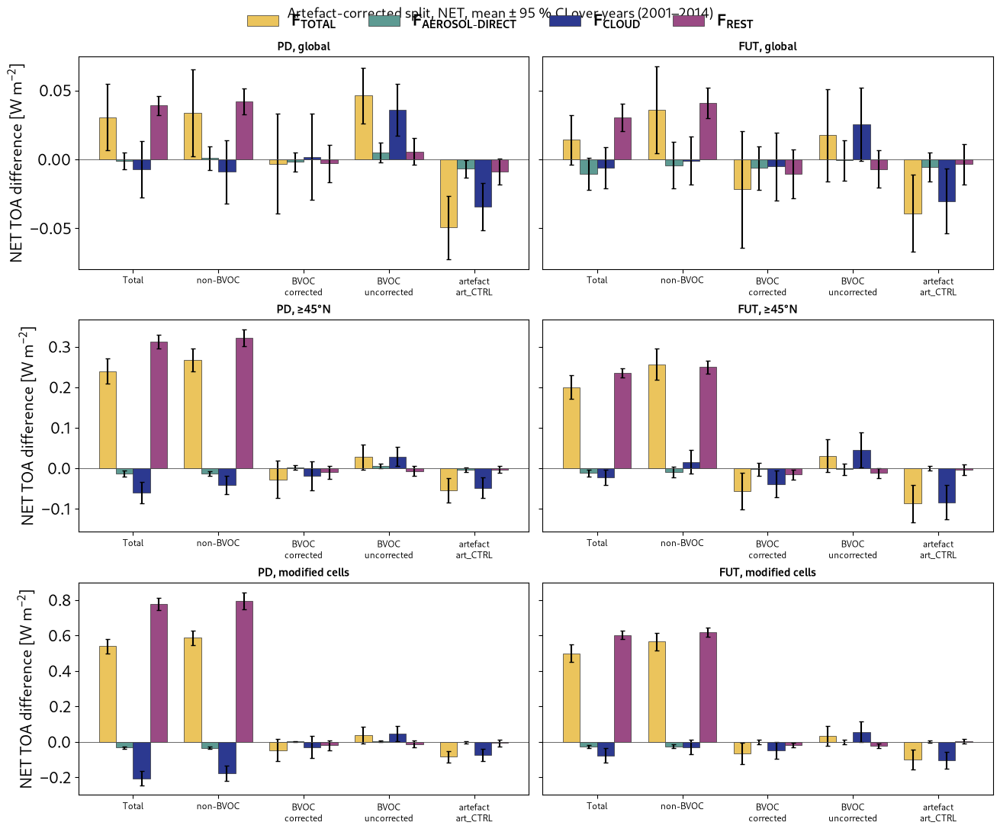

In [3]:
# NET budget bars: rows = regions, columns = periods; groups = contrasts, bars = Ghan terms (gold = total)
s = rad_s[rad_s.band == "NET"]
fig, axes = plt.subplots(len(REGIONS), 2, figsize=(13, 3.6 * len(REGIONS)), sharey="row", constrained_layout=True)
x = np.arange(len(ORDER)); wbar = 0.2
for i, region in enumerate(REGIONS):
    for j, P in enumerate(("PD", "FUT")):
        ax = axes[i, j]
        for k, term in enumerate(fm.GHAN_TERMS):
            sub = s[(s.region == region) & (s.period == P) & (s.term == term)].set_index("contrast").reindex(ORDER)
            name, color = fm.TERM_STYLE[term]
            ax.bar(x + (k - 1.5) * wbar, sub["mean"], wbar, yerr=sub["ci95"], color=color, edgecolor="0.2",
                   linewidth=0.5, capsize=2, label=name if (i, j) == (0, 0) else None)
        ax.axhline(0, color="0.3", lw=0.6)
        ax.set_xticks(x, [c.replace(" ", "\n", 1) for c in ORDER], fontsize=8.5)
        ax.set_title(f"{P}, {region}", fontsize=10.5, fontweight="semibold")
        if j == 0: ax.set_ylabel("NET TOA difference [W m$^{-2}$]")
fig.legend(loc="outside upper center", ncol=4, frameon=False)
fig.suptitle(f"Artefact-corrected split, NET, mean ± 95 % CI over years ({START_YEAR}–{END_YEAR})", fontsize=13)
fig.savefig(FIG / f"radiative_budget_split_NET_{START_YEAR}_{END_YEAR}.png", dpi=200, bbox_inches="tight")
plt.show(); plt.close(fig)

## 2. BVOC → SOA → aerosol → cloud chain: regional means, corrected vs uncorrected
Absolute difference and % of the CTRL_P mean of the same region. Emissions in mg m⁻² day⁻¹, SOA burden in mg m⁻² (`cbSOA_mgm2` interstitial, `cbSOA_all_mgm2` incl. cloud-borne), N_AER lowest level, in-cloud CDNC (cm⁻³), LWP (g m⁻²).

In [4]:
FIELDS = [("BVOC", "SFISOP_mgm2d"), ("BVOC", "SFMTERP_mgm2d"), ("SOA", "cbSOA_mgm2"), ("SOA", "cbSOA_all_mgm2"),
          ("SOA", "N_AER"), ("CLOUDPROP", "ACTNL_incld"), ("CLOUDPROP", "ACTREL_incld"), ("CLOUDPROP", "TGCLDLWP_gm2")]
rows = []
for P in ("PD", "FUT"):
    for cls, var in FIELDS:
        ref = fm.open_class(f"CTRL_{P}", cls, START_YEAR, END_YEAR)
        masks = masks_for(ref)
        base_map = fm.yearly_field(ref, var).mean("year")
        for label, (c1, c2) in contrasts(P).items():
            d = fm.yearly_difference(c1, c2, cls, var, START_YEAR, END_YEAR).load()
            for region in REGIONS:
                r = fm.regional(d, ref, masks[region]); base = float(fm.regional(base_map, ref, masks[region]))
                rows += [dict(period=P, field=var, region=region, contrast=label, year=int(y), value=float(v), baseline=base)
                         for y, v in zip(r["year"].values, r.values)]
chain = pd.DataFrame(rows)
chain.to_csv(TAB / f"chain_split_yearly_{START_YEAR}_{END_YEAR}.csv", index=False)
chain_s = fm.summarize_years(chain, ["period", "field", "region", "contrast"]).merge(
    chain.groupby(["period", "field", "region"])["baseline"].first().reset_index())
chain_s["pct"] = 100 * chain_s["mean"] / chain_s["baseline"]
chain_s["pct_ci95"] = 100 * chain_s["ci95"] / chain_s["baseline"].abs()
chain_s.to_csv(TAB / f"chain_split_{START_YEAR}_{END_YEAR}.csv", index=False)
w = chain.pivot_table(index=["period", "field", "region", "year"], columns="contrast", values="value")
print(f"chain closure Total − (non-BVOC + BVOC corr): {(w['Total'] - w['non-BVOC'] - w['BVOC corrected']).abs().max():.1e}")
pct = chain_s.assign(v=lambda t: t["pct"].map("{:+.2f}".format) + " ± " + t["pct_ci95"].map("{:.2f}".format))
pct.pivot_table(index=["region", "period", "field"], columns="contrast", values="v", aggfunc="first").reindex(columns=ORDER)

chain closure Total − (non-BVOC + BVOC corr): 3.3e-02


contrast                                     Total      non-BVOC BVOC corrected BVOC uncorrected artefact art_CTRL
region         period field                                                                                       
global         FUT    ACTNL_incld     +0.06 ± 0.17  +0.01 ± 0.15   +0.04 ± 0.23     -0.40 ± 0.20      +0.45 ± 0.22
                      ACTREL_incld    -0.05 ± 0.03  -0.01 ± 0.02   -0.03 ± 0.03     +0.12 ± 0.04      -0.15 ± 0.05
                      N_AER           +0.05 ± 0.06  +0.03 ± 0.07   +0.02 ± 0.05     -0.62 ± 0.14      +0.64 ± 0.15
                      SFISOP_mgm2d    +0.24 ± 0.18  +0.00 ± 0.00   +0.24 ± 0.18     +0.29 ± 0.75      -0.05 ± 0.81
                      SFMTERP_mgm2d   +0.15 ± 0.15  +0.00 ± 0.00   +0.15 ± 0.15     +0.19 ± 0.58      -0.05 ± 0.63
                      TGCLDLWP_gm2    -0.06 ± 0.03  -0.07 ± 0.06   +0.01 ± 0.07     -0.05 ± 0.05      +0.06 ± 0.05
                      cbSOA_all_mgm2  +0.19 ± 0.21  +0.02 ± 0.17   +0.17 ± 0.31     -2.58 ± 0.63      +2.75 ± 0.76
                      cbSOA_mgm2      +0.19 ± 0.20  +0.02 ± 0.17   +0.17 ± 0.30     -2.59 ± 0.63      +2.76 ± 0.76
               PD     ACTNL_incld     -0.01 ± 0.16  -0.03 ± 0.13   +0.04 ± 0.15     -0.33 ± 0.11      +0.35 ± 0.16
                      ACTREL_incld    -0.00 ± 0.02  -0.00 ± 0.03   -0.00 ± 0.03     +0.09 ± 0.03      -0.09 ± 0.03
                      N_AER           +0.07 ± 0.05  +0.04 ± 0.05   +0.03 ± 0.05     -0.21 ± 0.04      +0.24 ± 0.05
                      SFISOP_mgm2d    -0.09 ± 0.28  +0.00 ± 0.00   -0.09 ± 0.28     -0.04 ± 0.58      -0.05 ± 0.54
                      SFMTERP_mgm2d   -0.11 ± 0.22  +0.00 ± 0.00   -0.11 ± 0.22     -0.06 ± 0.50      -0.05 ± 0.46
                      TGCLDLWP_gm2    -0.09 ± 0.05  -0.06 ± 0.05   -0.03 ± 0.08     -0.07 ± 0.06      +0.04 ± 0.04
                      cbSOA_all_mgm2  -0.19 ± 0.38  +0.14 ± 0.23   -0.32 ± 0.51     -2.89 ± 0.64      +2.57 ± 0.41
                      cbSOA_mgm2      -0.19 ± 0.38  +0.14 ± 0.23   -0.33 ± 0.51     -2.90 ± 0.64      +2.58 ± 0.41
modified cells FUT    ACTNL_incld     +0.01 ± 0.13  -0.47 ± 0.17   +0.48 ± 0.21     -0.86 ± 0.44      +1.34 ± 0.41
                      ACTREL_incld    -0.23 ± 0.05  +0.10 ± 0.03   -0.33 ± 0.06     -0.03 ± 0.14      -0.30 ± 0.12
                      N_AER           +1.60 ± 0.10  +0.58 ± 0.05   +1.01 ± 0.12     -2.76 ± 0.90      +3.78 ± 0.95
                      SFISOP_mgm2d    +2.90 ± 0.58  +0.00 ± 0.00   +2.90 ± 0.58     +2.94 ± 3.91      -0.05 ± 3.79
                      SFMTERP_mgm2d   -0.53 ± 0.43  +0.00 ± 0.00   -0.53 ± 0.43     -0.48 ± 2.19      -0.05 ± 2.30
                      TGCLDLWP_gm2    -0.58 ± 0.09  -0.74 ± 0.10   +0.15 ± 0.11     +0.12 ± 0.14      +0.03 ± 0.14
                      cbSOA_all_mgm2  +0.54 ± 0.33  -0.05 ± 0.42   +0.59 ± 0.43     -1.73 ± 1.10      +2.32 ± 1.24
                      cbSOA_mgm2      +0.54 ± 0.33  -0.04 ± 0.42   +0.58 ± 0.43     -1.72 ± 1.09      +2.30 ± 1.23
               PD     ACTNL_incld     +0.17 ± 0.24  -0.23 ± 0.16   +0.40 ± 0.26     -0.67 ± 0.21      +1.07 ± 0.25
                      ACTREL_incld    -0.14 ± 0.07  +0.04 ± 0.06   -0.19 ± 0.07     +0.06 ± 0.06      -0.25 ± 0.07
                      N_AER           +1.57 ± 0.09  +0.69 ± 0.07   +0.88 ± 0.08     -1.73 ± 0.36      +2.61 ± 0.34
                      SFISOP_mgm2d    +5.83 ± 0.82  +0.00 ± 0.00   +5.83 ± 0.82     +5.87 ± 4.84      -0.05 ± 4.26
                      SFMTERP_mgm2d   +0.71 ± 0.41  +0.00 ± 0.00   +0.71 ± 0.41     +0.75 ± 2.26      -0.05 ± 2.24
                      TGCLDLWP_gm2    -0.53 ± 0.10  -0.65 ± 0.15   +0.12 ± 0.18     +0.04 ± 0.13      +0.08 ± 0.10
                      cbSOA_all_mgm2  +0.31 ± 0.70  +0.03 ± 0.53   +0.28 ± 1.07     -1.78 ± 1.20      +2.06 ± 1.04
                      cbSOA_mgm2      +0.30 ± 0.71  +0.04 ± 0.54   +0.25 ± 1.08     -1.76 ± 1.20      +2.01 ± 1.04
≥45°N          FUT    ACTNL_incld     +0.02 ± 0.10  -0.22 ± 0.10   +0.24 ± 0.17     -0.95 

## 3. Six-panel forcing summaries (BVOC panels corrected)
Panels 1–2 = LCC − CTRL (albedo proxy, total), panels 3–6 = corrected BVOC Ghan terms, LCC_P − (LCC_P^ctrlP − art). Per-panel scales and `split6-2` (albedo + total [−6, 6], BVOC terms [−2, 2]).

findfont: Failed to find font weight semibold, now using 700.
findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_NET_2001_2014.png


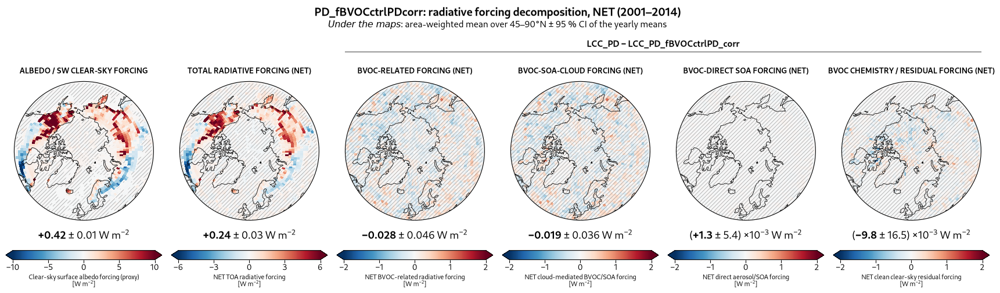

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_SW_2001_2014.png


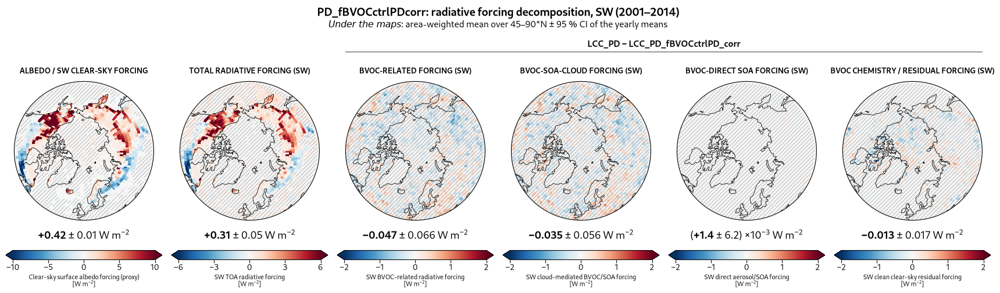

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_LW_2001_2014.png


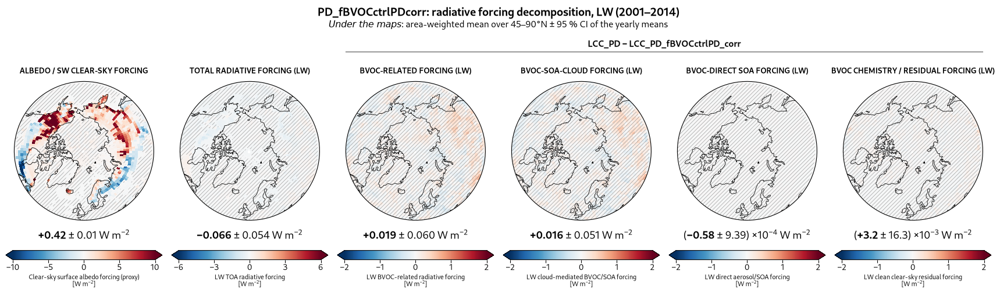

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_NET_split6-2_2001_2014.png


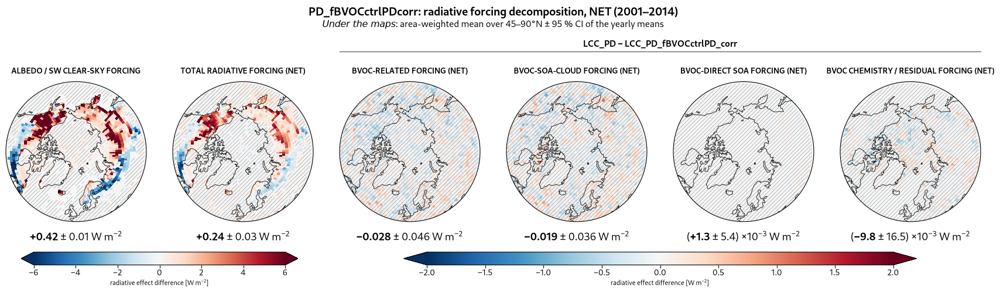

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_SW_split6-2_2001_2014.png


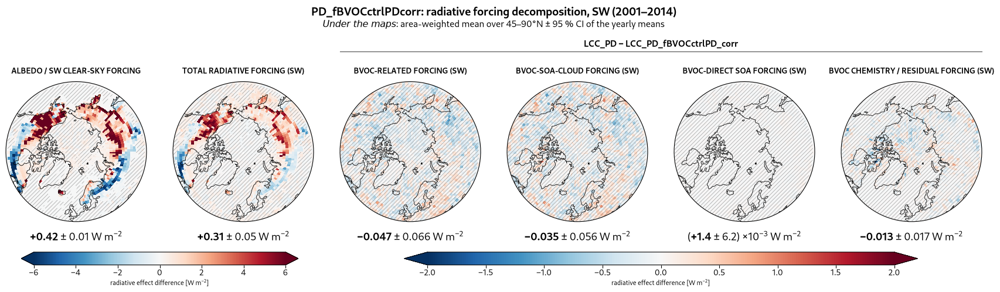

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_forcing_decomposition_LW_split6-2_2001_2014.png


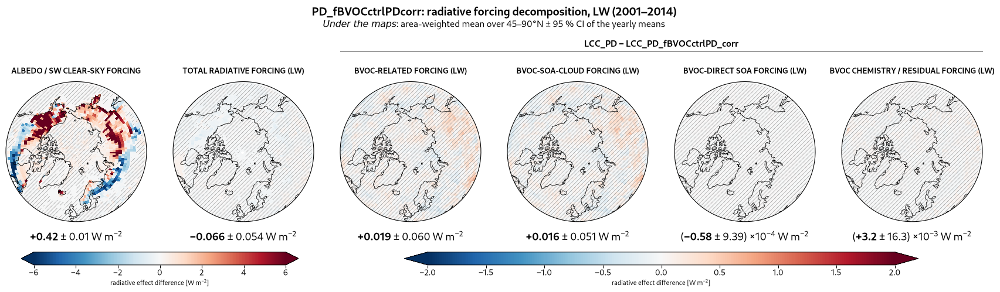

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_NET_2001_2014.png


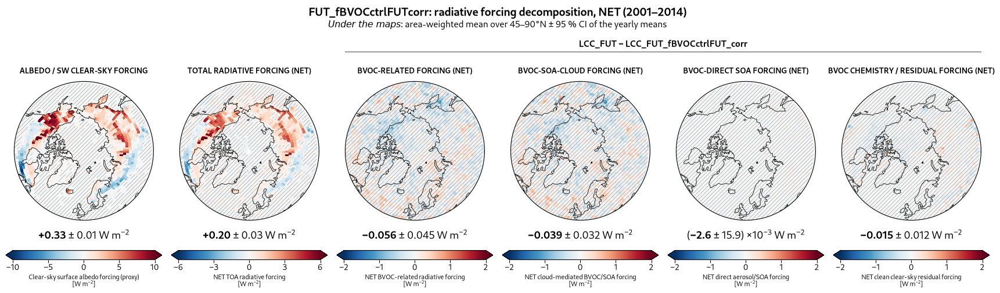

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_SW_2001_2014.png


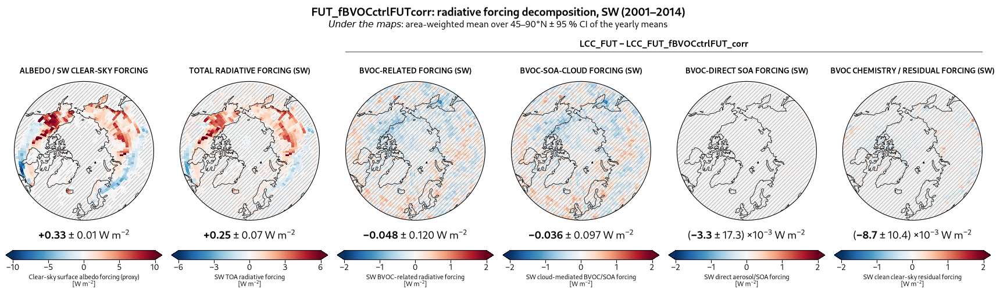

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_LW_2001_2014.png


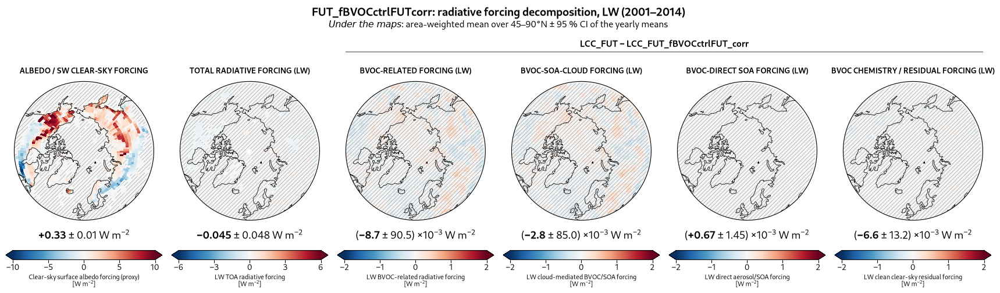

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_NET_split6-2_2001_2014.png


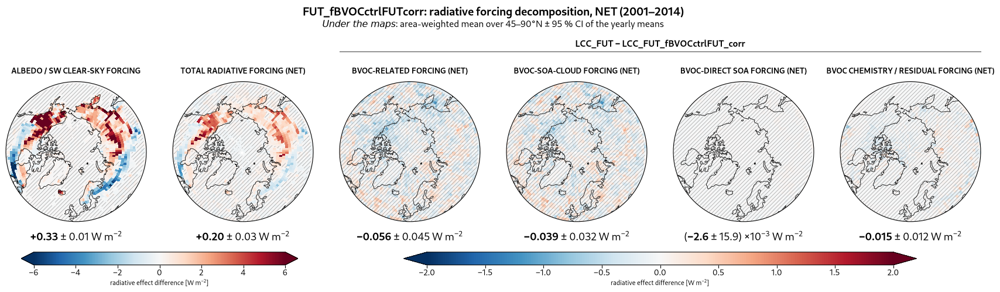

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_SW_split6-2_2001_2014.png


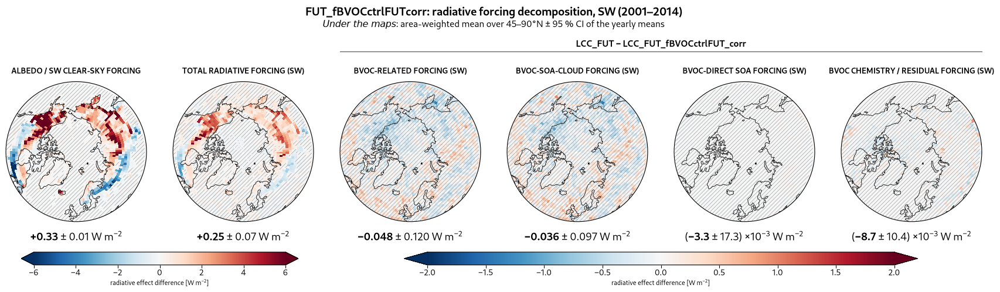

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_forcing_decomposition_LW_split6-2_2001_2014.png


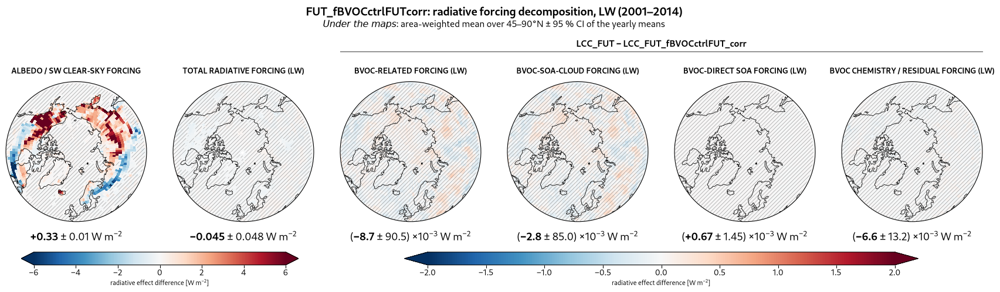

In [5]:
for P in ("PD", "FUT"):
    for scales in (None, "split6-2"):
        for band in ("NET", "SW", "LW"):
            fig, axes = fm.make_forcing_summary_figure(f"{P}_fBVOCctrl{P}corr", band=band, pairs=fm.CORRECTED_PAIRS[P],
                                                       scales=scales, transparent_background=True, **common)
            plt.show(); plt.close(fig)

## 4. Ghan decomposition maps: corrected BVOC and non-BVOC
Annual NET, SW, LW and seasonal NET. File names: `<P>_ghan[_seasonal]_BVOCcorr_<band>` and `<P>_ghan[_seasonal]_nonBVOC_<band>`.

Ghan closure PD LCC-fBVOC NET ANN: max |sum of terms - total| = 1.1e-05 W m-2


findfont: Failed to find font weight semibold, now using 700.


Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_BVOCcorr_NET_2001_2014.png


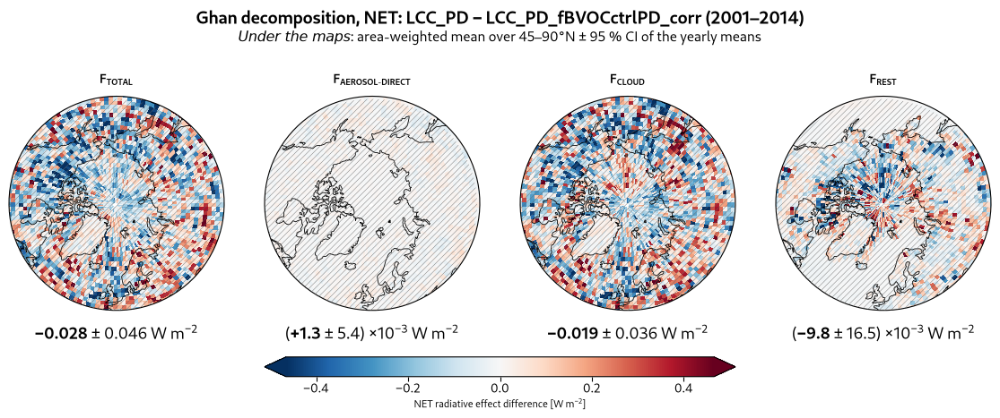

Ghan closure PD LCC-fBVOC SW ANN: max |sum of terms - total| = 1.9e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_BVOCcorr_SW_2001_2014.png


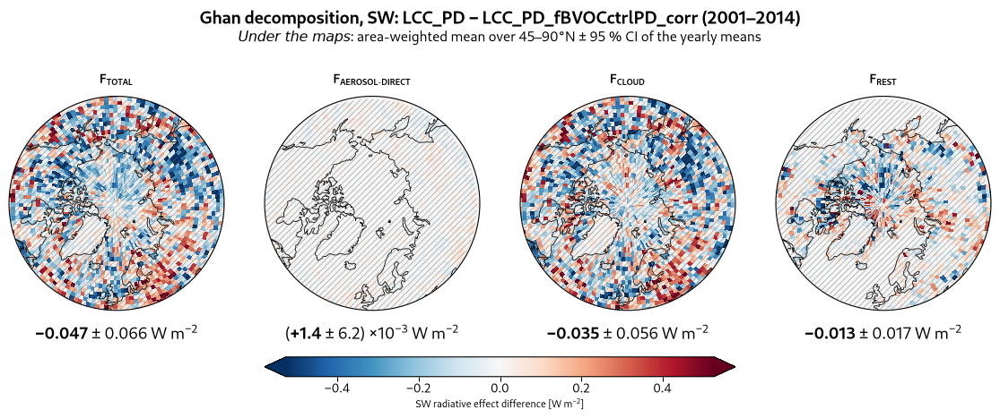

Ghan closure PD LCC-fBVOC LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_BVOCcorr_LW_2001_2014.png


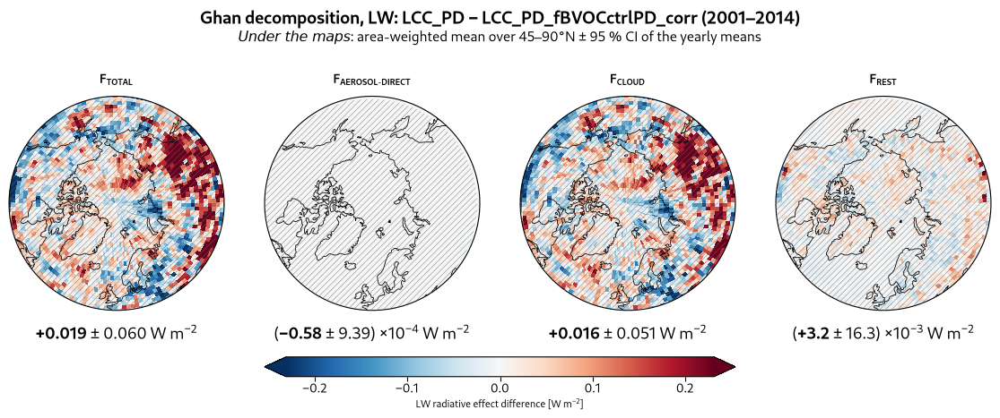

Ghan closure PD LCC-fBVOC NET DJF: max |sum of terms - total| = 2.9e-05 W m-2
Ghan closure PD LCC-fBVOC NET MAM: max |sum of terms - total| = 2.7e-05 W m-2
Ghan closure PD LCC-fBVOC NET JJA: max |sum of terms - total| = 2.9e-05 W m-2
Ghan closure PD LCC-fBVOC NET SON: max |sum of terms - total| = 2.6e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_seasonal_BVOCcorr_NET_2001_2014.png


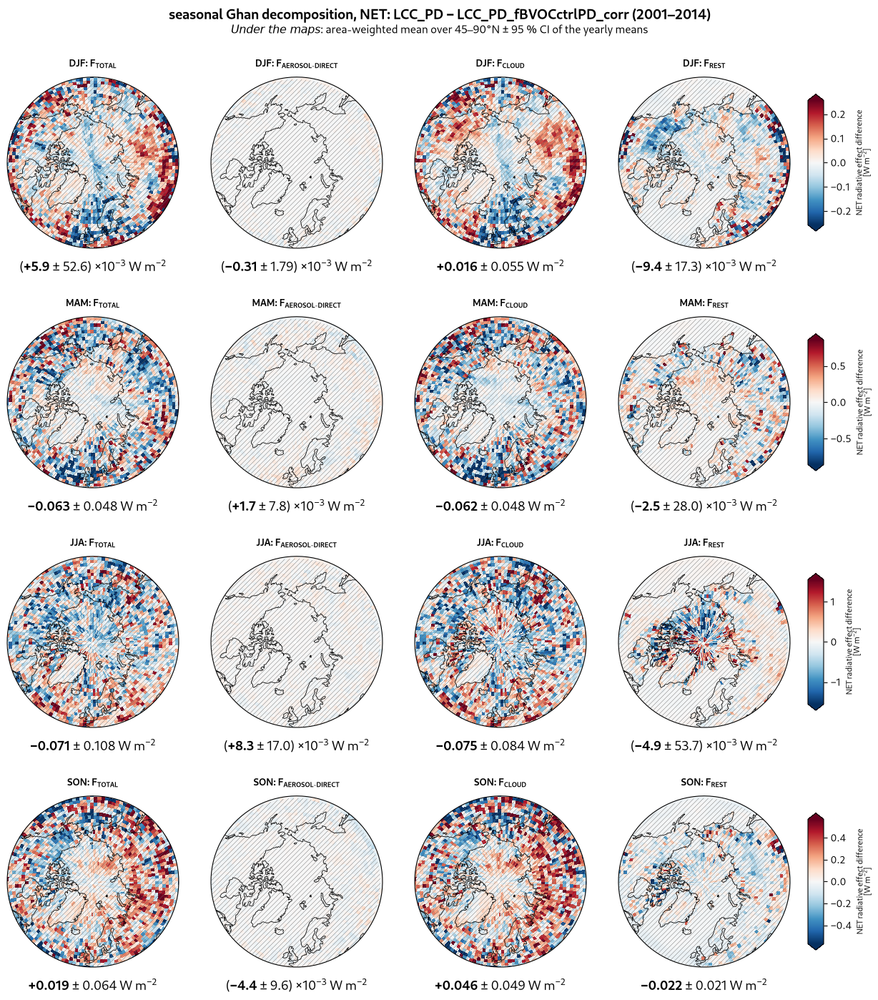

Ghan closure PD LCC-CTRL NET ANN: max |sum of terms - total| = 7.2e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_nonBVOC_NET_2001_2014.png


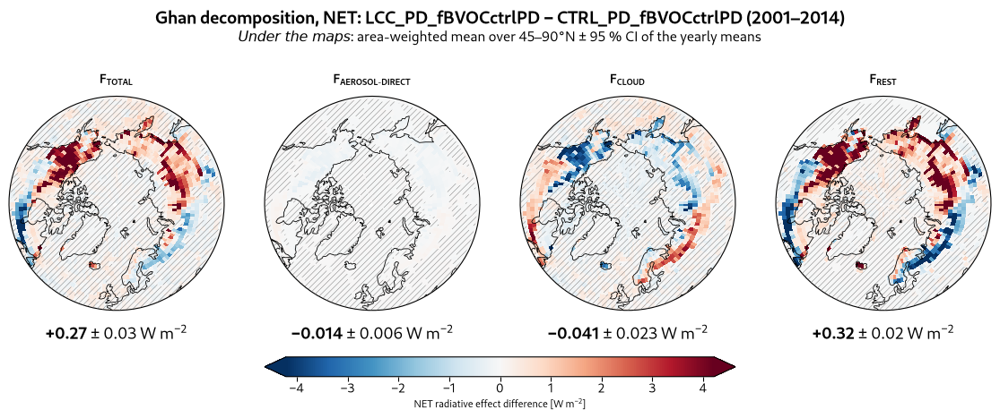

Ghan closure PD LCC-CTRL SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_nonBVOC_SW_2001_2014.png


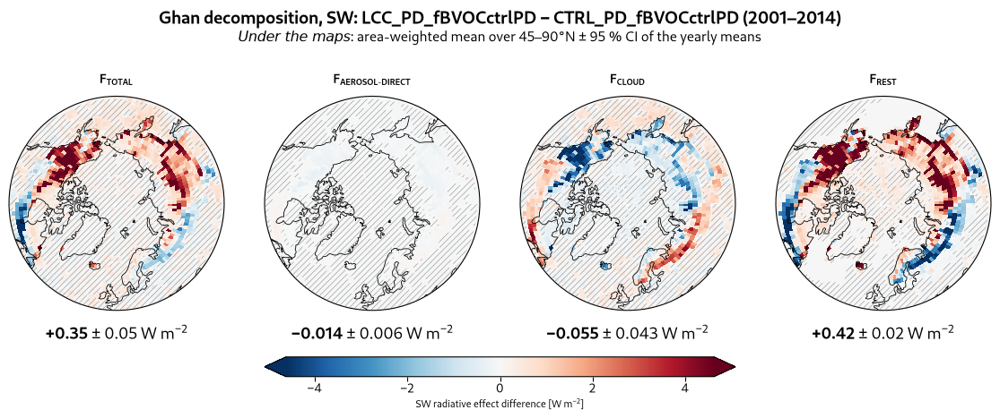

Ghan closure PD LCC-CTRL LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_nonBVOC_LW_2001_2014.png


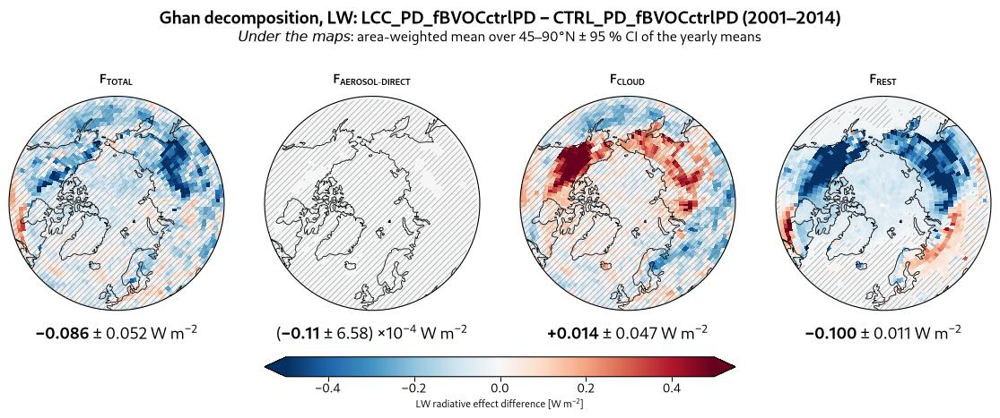

Ghan closure PD LCC-CTRL NET DJF: max |sum of terms - total| = 2.3e-05 W m-2
Ghan closure PD LCC-CTRL NET MAM: max |sum of terms - total| = 1.8e-05 W m-2
Ghan closure PD LCC-CTRL NET JJA: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure PD LCC-CTRL NET SON: max |sum of terms - total| = 1.9e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_ghan_seasonal_nonBVOC_NET_2001_2014.png


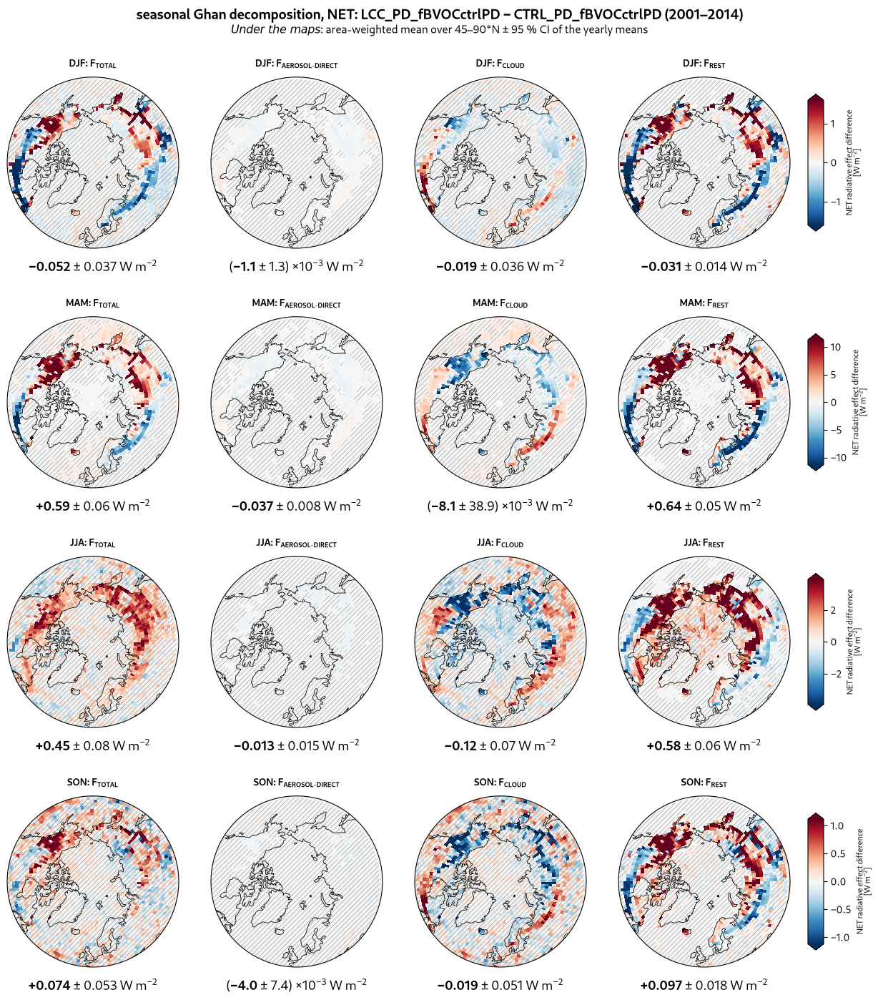

Ghan closure FUT LCC-fBVOC NET ANN: max |sum of terms - total| = 1.0e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_BVOCcorr_NET_2001_2014.png


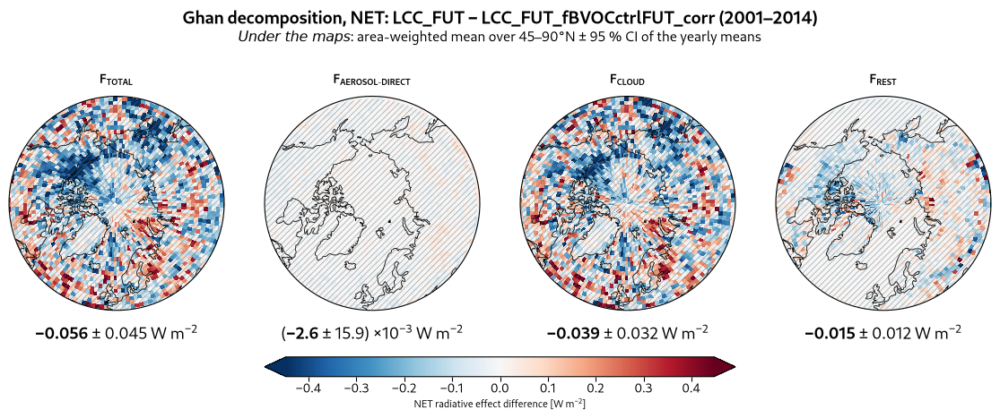

Ghan closure FUT LCC-fBVOC SW ANN: max |sum of terms - total| = 2.6e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_BVOCcorr_SW_2001_2014.png


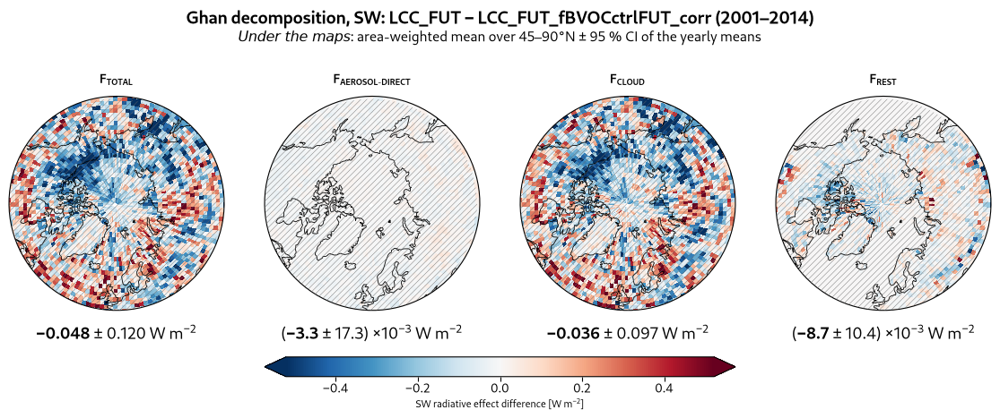

Ghan closure FUT LCC-fBVOC LW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_BVOCcorr_LW_2001_2014.png


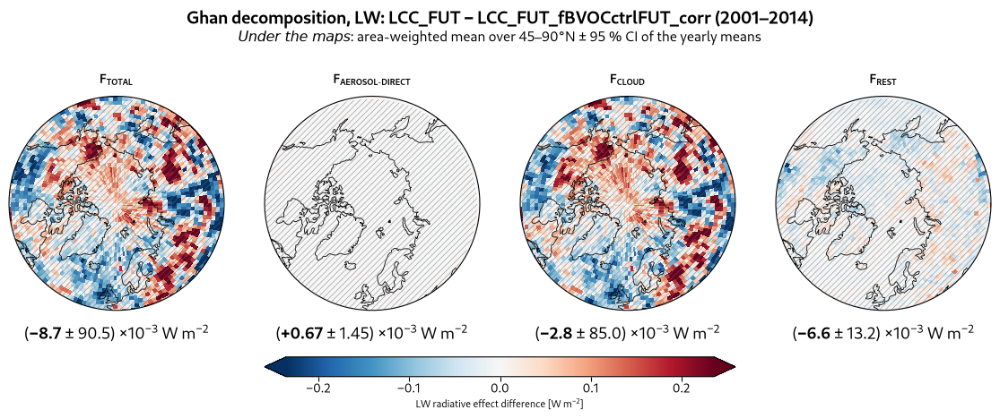

Ghan closure FUT LCC-fBVOC NET DJF: max |sum of terms - total| = 2.8e-05 W m-2
Ghan closure FUT LCC-fBVOC NET MAM: max |sum of terms - total| = 2.5e-05 W m-2
Ghan closure FUT LCC-fBVOC NET JJA: max |sum of terms - total| = 2.9e-05 W m-2
Ghan closure FUT LCC-fBVOC NET SON: max |sum of terms - total| = 2.8e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_seasonal_BVOCcorr_NET_2001_2014.png


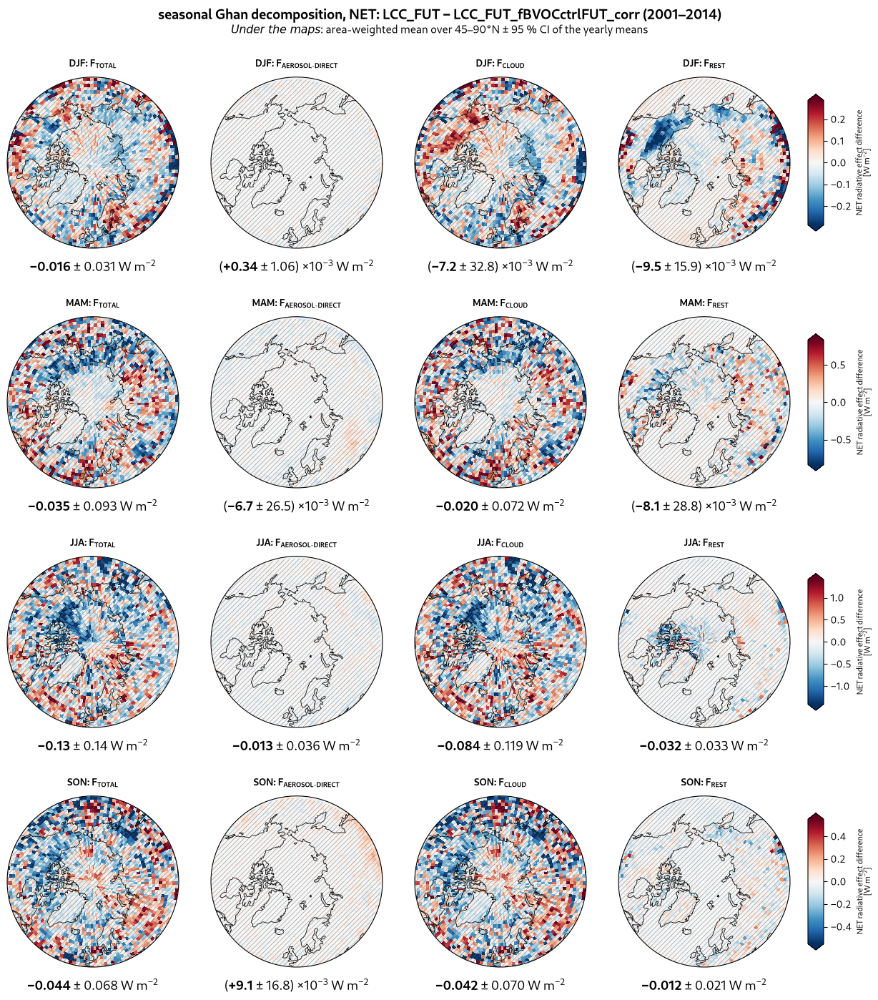

Ghan closure FUT LCC-CTRL NET ANN: max |sum of terms - total| = 6.5e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_nonBVOC_NET_2001_2014.png


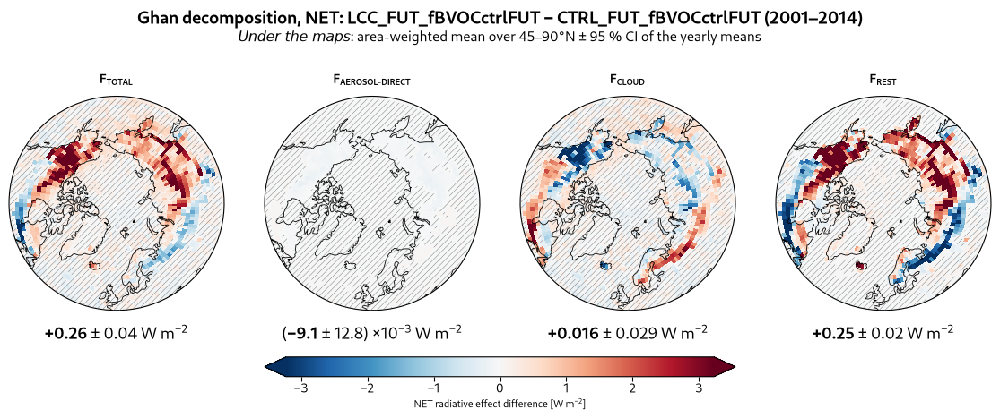

Ghan closure FUT LCC-CTRL SW ANN: max |sum of terms - total| = 1.3e-06 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_nonBVOC_SW_2001_2014.png


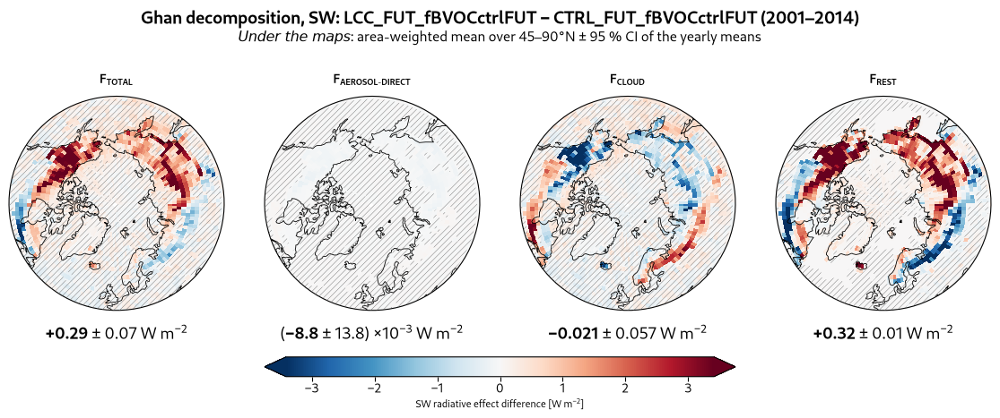

Ghan closure FUT LCC-CTRL LW ANN: max |sum of terms - total| = 6.5e-07 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_nonBVOC_LW_2001_2014.png


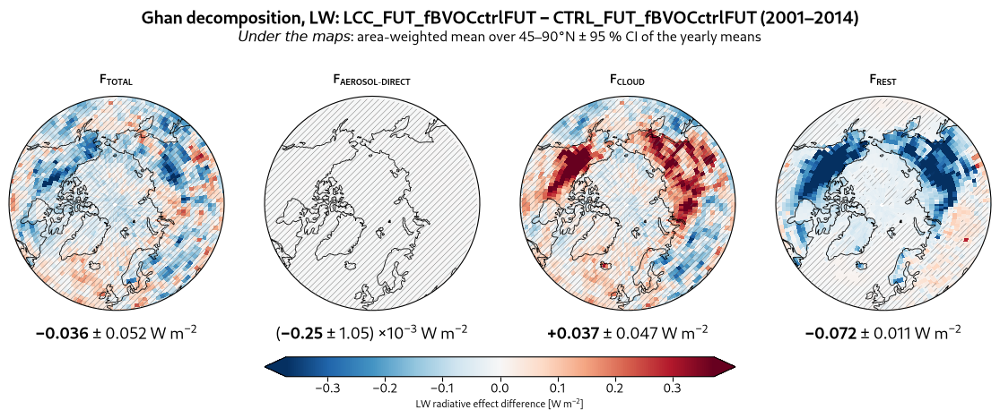

Ghan closure FUT LCC-CTRL NET DJF: max |sum of terms - total| = 1.8e-05 W m-2
Ghan closure FUT LCC-CTRL NET MAM: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure FUT LCC-CTRL NET JJA: max |sum of terms - total| = 2.0e-05 W m-2
Ghan closure FUT LCC-CTRL NET SON: max |sum of terms - total| = 1.8e-05 W m-2
Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_ghan_seasonal_nonBVOC_NET_2001_2014.png


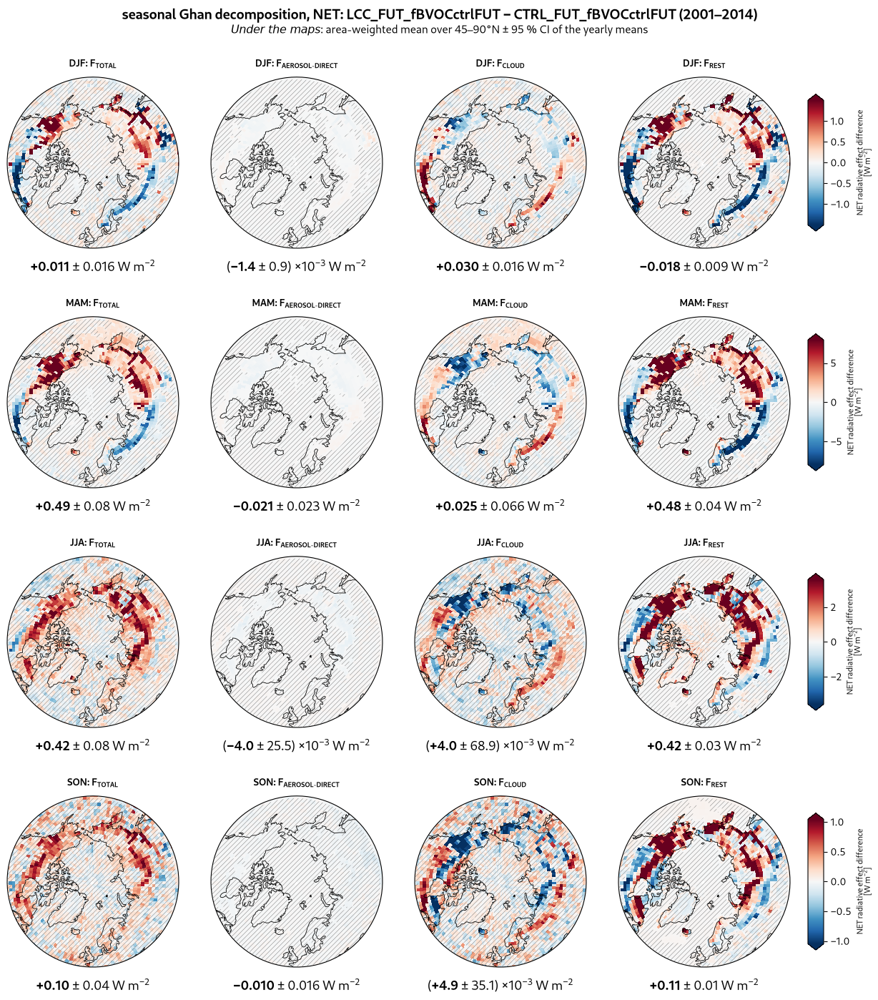

In [6]:
def ghan(P, which, band, seasonal):
    if which == "BVOCcorr":
        pairs, contrast = fm.CORRECTED_PAIRS[P], "bvoc"
    else:   # non-BVOC: LCC_P^ctrlP − CTRL_P^ctrlP, through the "total" roles
        pairs, contrast = {"lcc": f"LCC_{P}_fBVOCctrl{P}", "ctrl": f"CTRL_{P}_fBVOCctrl{P}", "fbvoc": None}, "total"
    fig, axes = fm.make_ghan_figure(P, contrast=contrast, band=band, seasonal=seasonal, pairs=pairs,
                                    start_year=START_YEAR, end_year=END_YEAR, extent_lat=45, mean_lat_min=45, save=False)
    path = FIG / f"{P}_ghan_{'seasonal_' if seasonal else ''}{which}_{band}_{START_YEAR}_{END_YEAR}.png"
    fig.savefig(path, dpi=300, bbox_inches="tight"); print("Saved", path)
    plt.show(); plt.close(fig)

for P in ("PD", "FUT"):
    for which in ("BVOCcorr", "nonBVOC"):
        for band in ("NET", "SW", "LW"):
            ghan(P, which, band, seasonal=False)
        ghan(P, which, "NET", seasonal=True)

## 5. Context maps of the corrected BVOC effect
Emissions → SOA → N_AER → cloud → ET, corrected BVOC contrast (`CONTEXT_PANELS`).

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/PD_fBVOCctrlPDcorr_bvoc_context_maps_2001_2014.png


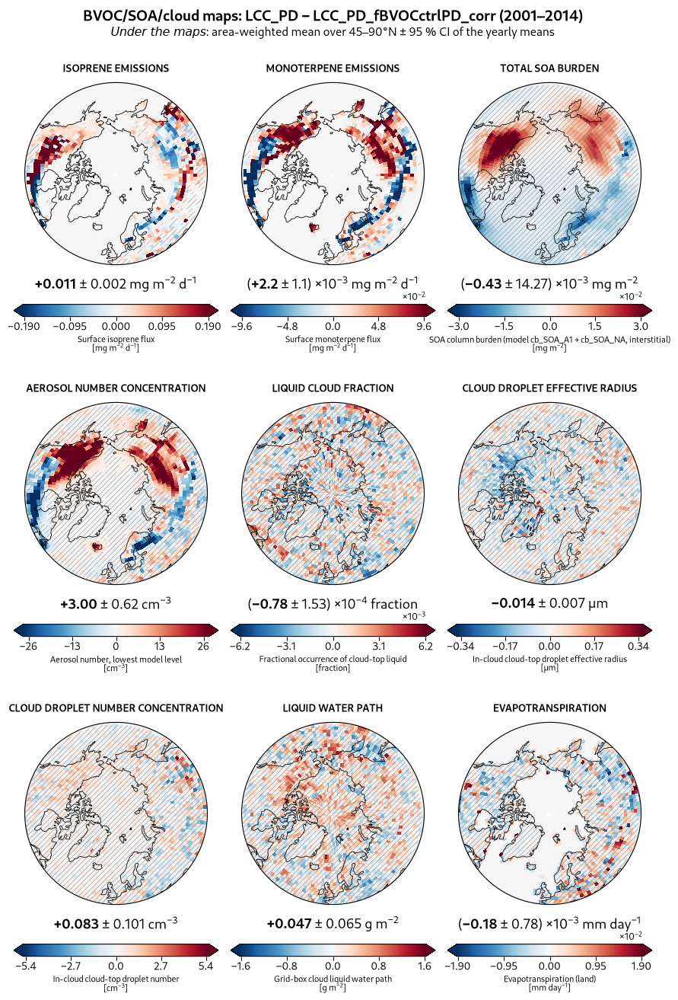

Saved /cluster/home/adelez/BOREAL-FOREST-EXPANSION/results/figures/artefact-corrected-split/FUT_fBVOCctrlFUTcorr_bvoc_context_maps_2001_2014.png


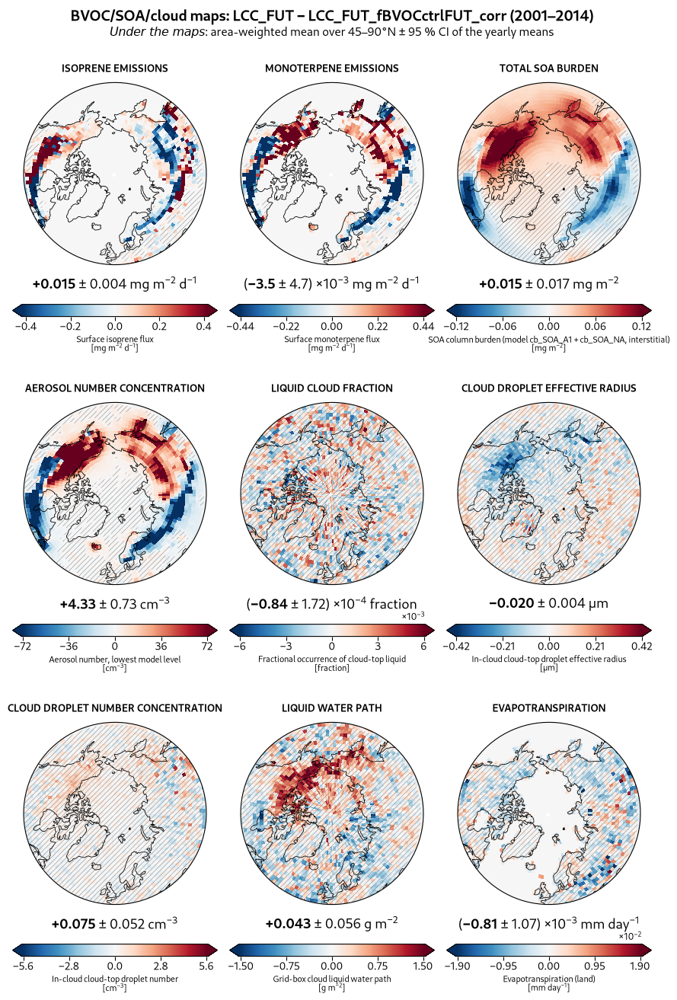

In [7]:
for P in ("PD", "FUT"):
    fig, axes = fm.make_context_maps_figure(f"{P}_fBVOCctrl{P}corr", pairs=fm.CORRECTED_PAIRS[P], **common)
    plt.show(); plt.close(fig)

## 6. Findings
_Filled after the run (numbers from the tables above, with evidence tags)._